=== FEATURE SELECTION PERFORMANCE BY k (CV on X_train) ===
 k  mean_log_loss  std_log_loss  mean_roc_auc  std_roc_auc
 1       1.395838      0.008066      0.861244     0.002222
 2       0.776107      0.007985      0.956749     0.001669
 3       0.702487      0.016100      0.959906     0.001837
 4       0.398460      0.011753      0.983283     0.000860
 5       0.356054      0.011502      0.985469     0.000664
 6       0.205761      0.018080      0.996770     0.000726
 7       0.191671      0.016225      0.997079     0.000813
 8       0.175492      0.015627      0.997521     0.000675


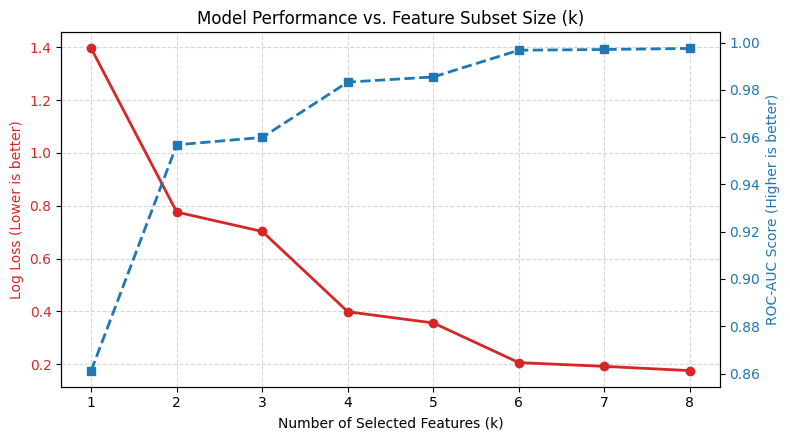

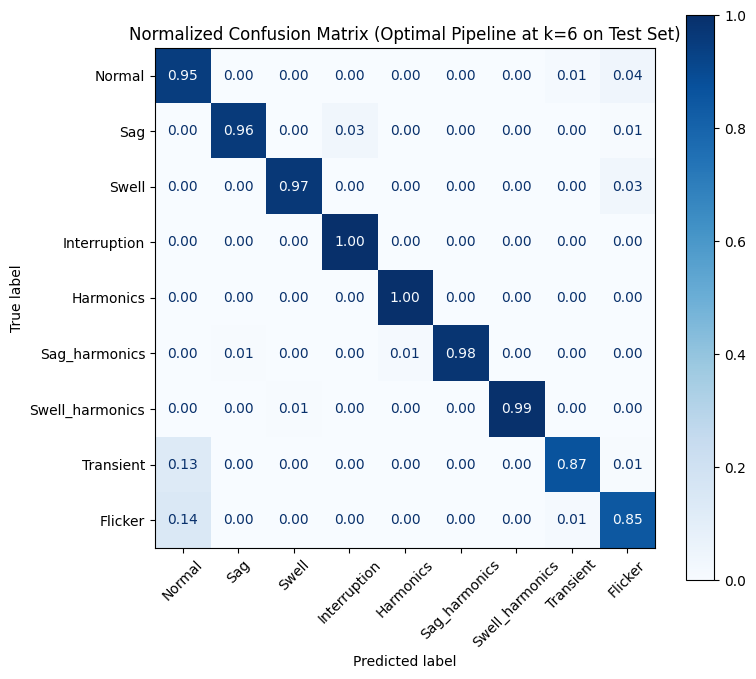

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from import_folder import PQD_INDICES, import_all_noiselevel_data

# -----------------------------------------------------------------------------
# 1. Load Data Across All Noise Levels & Create Isolated Holdout Split
# -----------------------------------------------------------------------------
folders = ["SNR_noiseless", "SNR_50dB", "SNR_40dB", "SNR_30dB", "SNR_20dB"]
all_data = import_all_noiselevel_data(folders, add_noise_column=False)

X = all_data.drop(columns=["label"])
y = all_data["label"]

# Strict Holdout Split BEFORE Any Cross-Validation or Feature Selection
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

CLASS_NAMES = {v: k for k, v in PQD_INDICES.items()}
class_labels = [CLASS_NAMES[i] for i in sorted(y.unique())]

# -----------------------------------------------------------------------------
# 2. Evaluate k=1 to 8 Features via Stratified 5-Fold Cross-Validation (X_train)
# -----------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for k in range(1, X_train.shape[1] + 1):
    fold_losses, fold_aucs = [], []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_train_cv, X_val_cv = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_train_cv, y_val_cv = y_train.iloc[train_idx], y_train.iloc[val_idx]

        pipeline_cv = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("select_k", SelectKBest(score_func=f_classif, k=k)),
                (
                    "classifier",
                    LogisticRegression(max_iter=1000, random_state=42),
                ),
            ]
        )

        pipeline_cv.fit(X_train_cv, y_train_cv)
        y_probs = pipeline_cv.predict_proba(X_val_cv)

        fold_losses.append(log_loss(y_val_cv, y_probs))
        fold_aucs.append(
            roc_auc_score(
                y_val_cv, y_probs, multi_class="ovr", average="macro"
            )
        )

    results.append(
        {
            "k": k,
            "mean_log_loss": np.mean(fold_losses),
            "std_log_loss": np.std(fold_losses),
            "mean_roc_auc": np.mean(fold_aucs),
            "std_roc_auc": np.std(fold_aucs),
        }
    )

results_df = pd.DataFrame(results)
print("=== FEATURE SELECTION PERFORMANCE BY k (CV on X_train) ===")
print(results_df.to_string(index=False))

# -----------------------------------------------------------------------------
# 3. Plot Performance Curve (Log Loss & ROC-AUC vs. k)
# -----------------------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(8, 4.5))

color = "tab:red"
ax1.set_xlabel("Number of Selected Features (k)")
ax1.set_ylabel("Log Loss (Lower is better)", color=color)
ax1.plot(
    results_df["k"],
    results_df["mean_log_loss"],
    marker="o",
    color=color,
    linewidth=2,
)
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("ROC-AUC Score (Higher is better)", color=color)
ax2.plot(
    results_df["k"],
    results_df["mean_roc_auc"],
    marker="s",
    color=color,
    linewidth=2,
    linestyle="--",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Model Performance vs. Feature Subset Size (k)")
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 4. Train Final Pipeline on k=6 and Plot Normalized Confusion Matrix (X_test)
# -----------------------------------------------------------------------------
final_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("select_k", SelectKBest(score_func=f_classif, k=6)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_labels,
    xticks_rotation=45,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=ax,
)
plt.title("Normalized Confusion Matrix (Optimal Pipeline at k=6 on Test Set)")
plt.tight_layout()
plt.show()

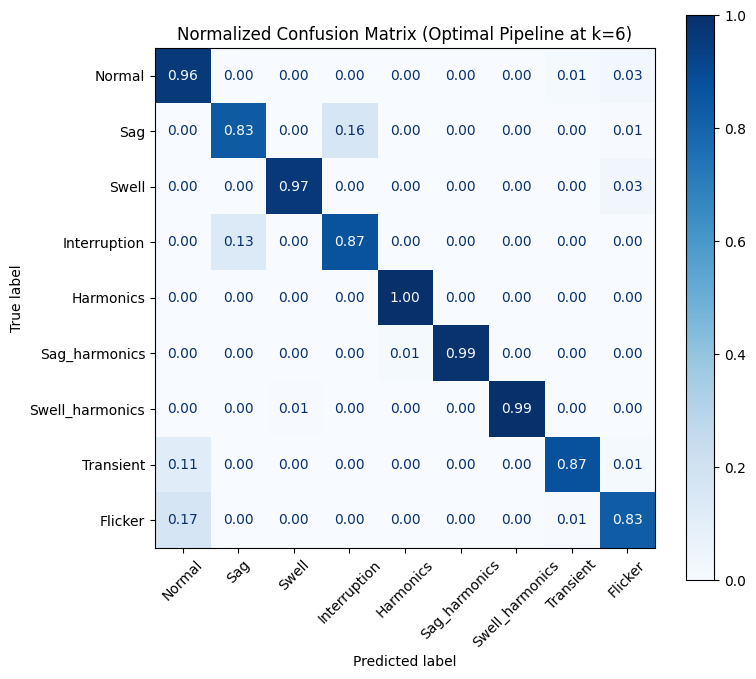

In [10]:
from sklearn.feature_selection import mutual_info_classif

# Pipeline using Mutual Information feature selection
mi_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("select_k", SelectKBest(score_func=mutual_info_classif, k=6)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

mi_pipeline.fit(X_train, y_train)
y_pred = mi_pipeline.predict(X_test)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_labels,
    xticks_rotation=45,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=ax,
)
plt.title("Normalized Confusion Matrix (Optimal Pipeline at k=6)")
plt.tight_layout()
plt.show()

=== GLOBAL PERFORMANCE COMPARISON (k=6 Features) ===
                       Model  Accuracy (%)  Log Loss  ROC-AUC
Logistic Regression (Linear)      95.07830  0.181391 0.997922
  Random Forest (Non-Linear)      97.53915  0.076592 0.999236


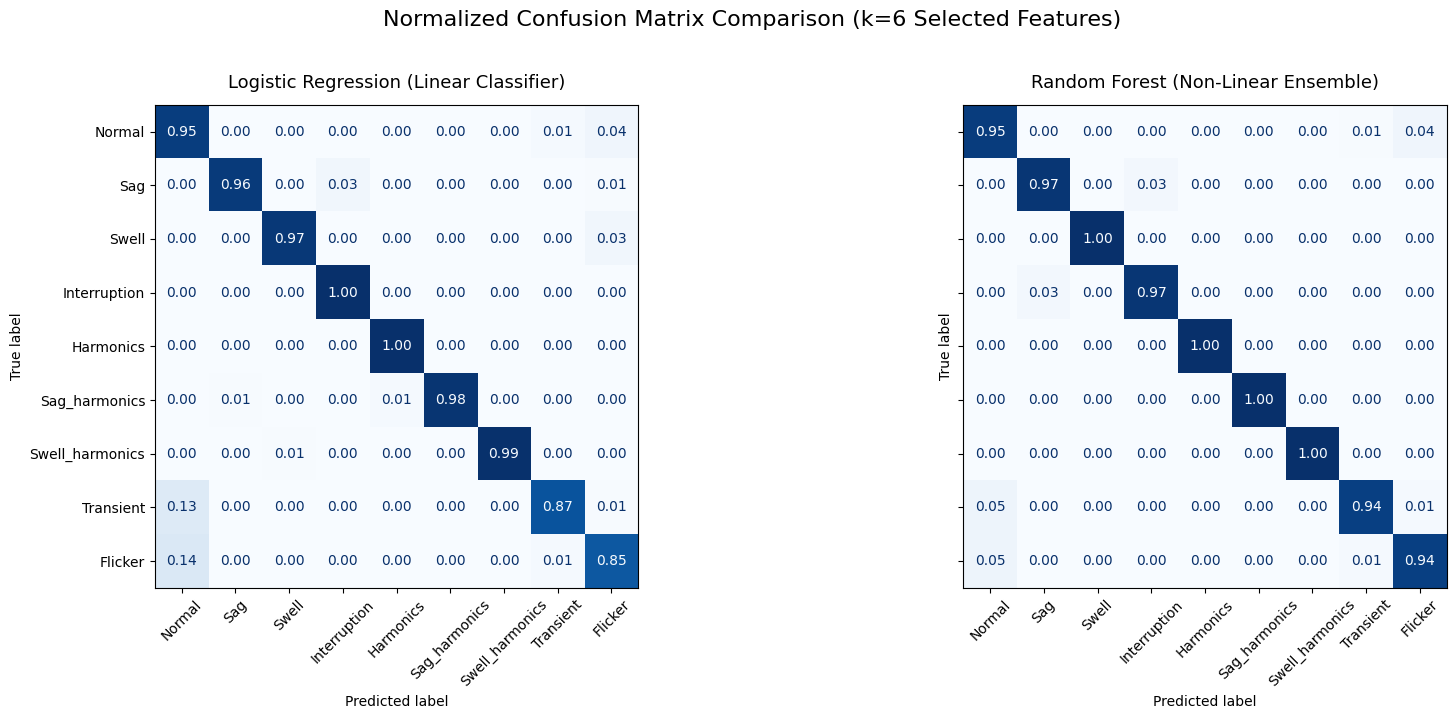

In [11]:
## THE COMPARISONS BELOW ARE DONE USING TEST DATA AND THUS CAUSE DATA LEAKAGE.
## They are only for demonstration purposes and should not be used for selection!

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from import_folder import PQD_INDICES, import_all_noiselevel_data

# -----------------------------------------------------------------------------
# 1. Load Data Across All Noise Levels & Prepare Split
# -----------------------------------------------------------------------------
folders = ["SNR_noiseless", "SNR_50dB", "SNR_40dB", "SNR_30dB", "SNR_20dB"]
all_data = import_all_noiselevel_data(folders, add_noise_column=False)

X = all_data.drop(columns=["label"])
y = all_data["label"]

CLASS_NAMES = {v: k for k, v in PQD_INDICES.items()}
class_labels = [CLASS_NAMES[i] for i in sorted(y.unique())]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------------------------------------------------------
# 2. Define Pipelines (Logistic Regression vs. Random Forest)
# -----------------------------------------------------------------------------
pipeline_lr = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("select_k", SelectKBest(score_func=f_classif, k=6)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

pipeline_rf = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("select_k", SelectKBest(score_func=f_classif, k=6)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
            ),
        ),
    ]
)

# -----------------------------------------------------------------------------
# 3. Fit Pipelines & Evaluate Global Metrics
# -----------------------------------------------------------------------------
pipeline_lr.fit(X_train, y_train)
pipeline_rf.fit(X_train, y_train)

y_probs_lr = pipeline_lr.predict_proba(X_test)
y_preds_lr = pipeline_lr.predict(X_test)

y_probs_rf = pipeline_rf.predict_proba(X_test)
y_preds_rf = pipeline_rf.predict(X_test)

comparison_metrics = pd.DataFrame(
    [
        {
            "Model": "Logistic Regression (Linear)",
            "Accuracy (%)": accuracy_score(y_test, y_preds_lr) * 100,
            "Log Loss": log_loss(y_test, y_probs_lr),
            "ROC-AUC": roc_auc_score(
                y_test, y_probs_lr, multi_class="ovr", average="macro"
            ),
        },
        {
            "Model": "Random Forest (Non-Linear)",
            "Accuracy (%)": accuracy_score(y_test, y_preds_rf) * 100,
            "Log Loss": log_loss(y_test, y_probs_rf),
            "ROC-AUC": roc_auc_score(
                y_test, y_probs_rf, multi_class="ovr", average="macro"
            ),
        },
    ]
)

print("=== GLOBAL PERFORMANCE COMPARISON (k=6 Features) ===")
print(comparison_metrics.to_string(index=False))

# -----------------------------------------------------------------------------
# 4. Plot Side-by-Side Normalized Confusion Matrices
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Panel 1: Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_preds_lr,
    display_labels=class_labels,
    xticks_rotation=45,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title(
    "Logistic Regression (Linear Classifier)", fontsize=13, pad=12
)

# Panel 2: Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_preds_rf,
    display_labels=class_labels,
    xticks_rotation=45,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title(
    "Random Forest (Non-Linear Ensemble)", fontsize=13, pad=12
)

plt.suptitle(
    "Normalized Confusion Matrix Comparison (k=6 Selected Features)",
    fontsize=16,
    y=1.02,
)
plt.tight_layout()
plt.show()

=== SELECTED FEATURES COMPARISON ===
ANOVA F-Score Top 6  : ['F1:avg_abs_ST_3rd', 'F2:std_TmA', 'F3:max_TmA', 'F4:min_TmA', 'F7:std_FmA_gt3', 'F8:near_zero_cnt']
Mutual Info Top 6    : ['F1:avg_abs_ST_3rd', 'F2:std_TmA', 'F3:max_TmA', 'F4:min_TmA', 'F6:std_FmA_3_7', 'F7:std_FmA_gt3']


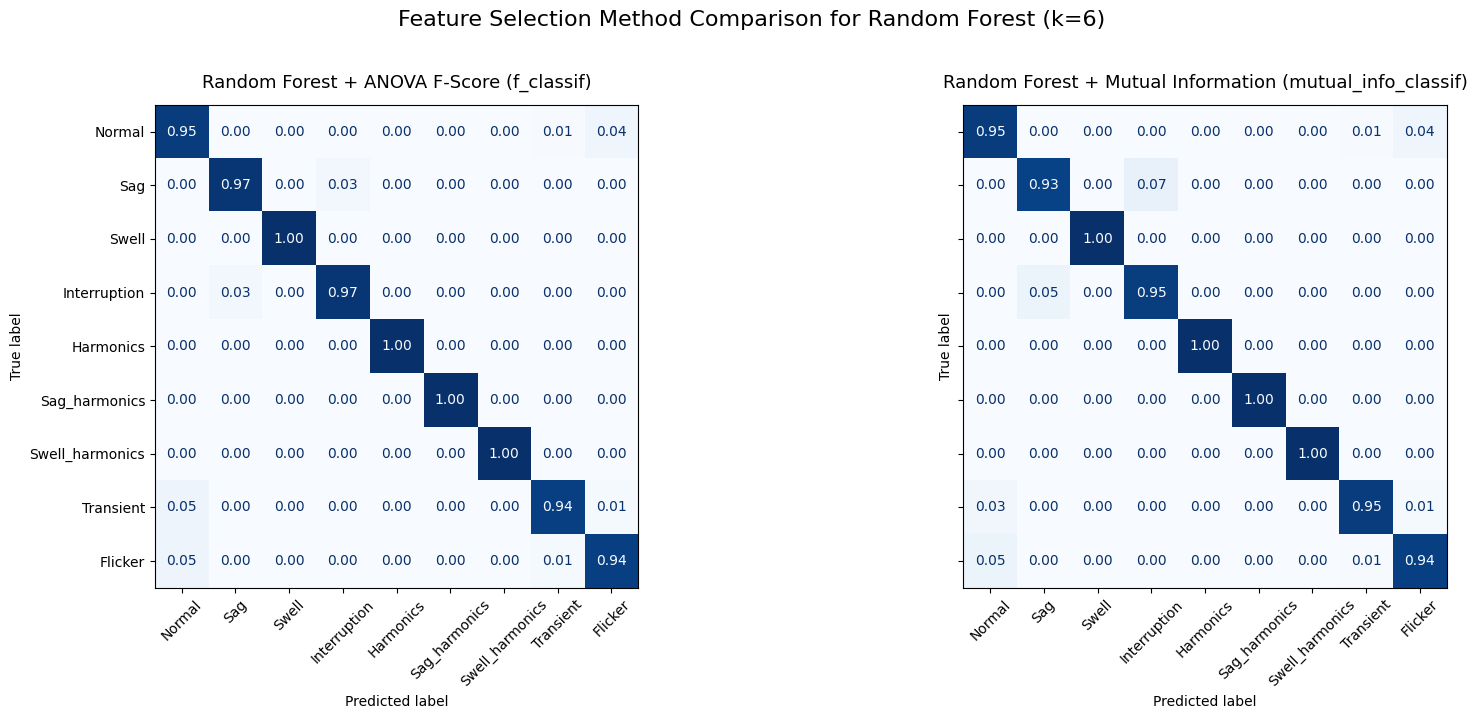

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from import_folder import PQD_INDICES, import_all_noiselevel_data

# 1. Load Data
folders = ["SNR_noiseless", "SNR_50dB", "SNR_40dB", "SNR_30dB", "SNR_20dB"]
all_data = import_all_noiselevel_data(folders, add_noise_column=False)

X = all_data.drop(columns=["label"])
y = all_data["label"]

CLASS_NAMES = {v: k for k, v in PQD_INDICES.items()}
class_labels = [CLASS_NAMES[i] for i in sorted(y.unique())]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Define Pipelines
rf_anova = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("select_k", SelectKBest(score_func=f_classif, k=6)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
            ),
        ),
    ]
)

rf_mi = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("select_k", SelectKBest(score_func=mutual_info_classif, k=6)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
            ),
        ),
    ]
)

# 3. Fit & Predict
rf_anova.fit(X_train, y_train)
rf_mi.fit(X_train, y_train)

y_preds_anova = rf_anova.predict(X_test)
y_preds_mi = rf_mi.predict(X_test)

# 4. Compare Selected Features
anova_selected = X.columns[rf_anova.named_steps["select_k"].get_support()]
mi_selected = X.columns[rf_mi.named_steps["select_k"].get_support()]

print("=== SELECTED FEATURES COMPARISON ===")
print(f"ANOVA F-Score Top 6  : {list(anova_selected)}")
print(f"Mutual Info Top 6    : {list(mi_selected)}")

# 5. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_preds_anova,
    display_labels=class_labels,
    xticks_rotation=45,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title(
    "Random Forest + ANOVA F-Score (f_classif)", fontsize=13, pad=12
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_preds_mi,
    display_labels=class_labels,
    xticks_rotation=45,
    cmap="Blues",
    normalize="true",
    values_format=".2f",
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title(
    "Random Forest + Mutual Information (mutual_info_classif)",
    fontsize=13,
    pad=12,
)

plt.suptitle(
    "Feature Selection Method Comparison for Random Forest (k=6)",
    fontsize=16,
    y=1.02,
)
plt.tight_layout()
plt.show()